# COTTONIL Data Analysis

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
sales = pd.read_csv('COTTONIL_Data/02_TABLES/sales_orders.csv')

# EDA

In [3]:
sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 540000 entries, 0 to 539999
Data columns (total 13 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   sales_order_id      540000 non-null  str    
 1   order_date          540000 non-null  str    
 2   branch_id           540000 non-null  str    
 3   customer_id         437039 non-null  str    
 4   sales_channel       540000 non-null  str    
 5   payment_method      540000 non-null  str    
 6   items_count         540000 non-null  int64  
 7   gross_EGP           540000 non-null  float64
 8   discount_EGP        540000 non-null  float64
 9   net_before_tax_EGP  540000 non-null  float64
 10  tax_EGP             540000 non-null  float64
 11  paid_total_EGP      540000 non-null  float64
 12  status              540000 non-null  str    
dtypes: float64(5), int64(1), str(7)
memory usage: 83.9 MB


In [4]:
sales.describe()

,items_count,gross_EGP,discount_EGP,net_before_tax_EGP,tax_EGP,paid_total_EGP
count,540000.000000,540000.000000,540000.000000,540000.000000,540000.000000,540000.000000
mean,2.108400,1628.140327,70.225186,1557.915141,218.108202,1776.023343
std,1.007354,3568.668944,234.344561,3417.243525,478.414100,3895.657625
min,1.000000,12.990000,0.000000,11.690000,1.640000,13.330000
25%,1.000000,299.940000,0.000000,286.577500,40.120000,326.697500
50%,2.000000,703.300000,18.060000,672.590000,94.160000,766.750000
75%,3.000000,1654.632500,60.670000,1583.882500,221.740000,1805.622500
max,5.000000,244799.340000,48794.940000,210446.070000,29462.450000,239908.520000


In [5]:
sales.shape

(540000, 13)

In [6]:
sales['order_date'] = pd.to_datetime(sales['order_date'])

In [7]:
sales['sales_channel'].value_counts()

sales_channel
Retail POS              388171
E-commerce               97660
Wholesale / reseller     54169
Name: count, dtype: int64

In [8]:
sales['payment_method'].value_counts()

payment_method
Cash                215552
Card POS            183239
Wallet               59714
Cash on delivery     43476
Bank transfer        38019
Name: count, dtype: int64

In [9]:
sales['status'].value_counts()

status
Completed             448120
Delivered              81152
Partially returned     10728
Name: count, dtype: int64

In [10]:
sales['year'] = sales['order_date'].dt.year

In [11]:
sales['year'].unique()

array([2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026], dtype=int32)

In [12]:
sales['month'] = sales['order_date'].dt.month
sales['month'] = pd.to_datetime(sales[['year', 'month']].assign(DAY=1))

In [13]:
sales[['month']].head()

,month
0,2018-10-01
1,2018-10-01
2,2018-10-01
3,2018-10-01
4,2018-10-01


In [14]:
sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 540000 entries, 0 to 539999
Data columns (total 15 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   sales_order_id      540000 non-null  str           
 1   order_date          540000 non-null  datetime64[us]
 2   branch_id           540000 non-null  str           
 3   customer_id         437039 non-null  str           
 4   sales_channel       540000 non-null  str           
 5   payment_method      540000 non-null  str           
 6   items_count         540000 non-null  int64         
 7   gross_EGP           540000 non-null  float64       
 8   discount_EGP        540000 non-null  float64       
 9   net_before_tax_EGP  540000 non-null  float64       
 10  tax_EGP             540000 non-null  float64       
 11  paid_total_EGP      540000 non-null  float64       
 12  status              540000 non-null  str           
 13  year                540000 non-null  int

## YTD Growth (Year-to-Date Growth)

In [15]:
sales_2018 = sales[sales['year'] == 2018]

In [16]:
monthly_sales_2018 = (
    sales_2018.groupby("month")
    .agg(
        Total_Units=("items_count", "sum"),
        Revenue=("paid_total_EGP", "sum"),
        
    )
    .reset_index()
)

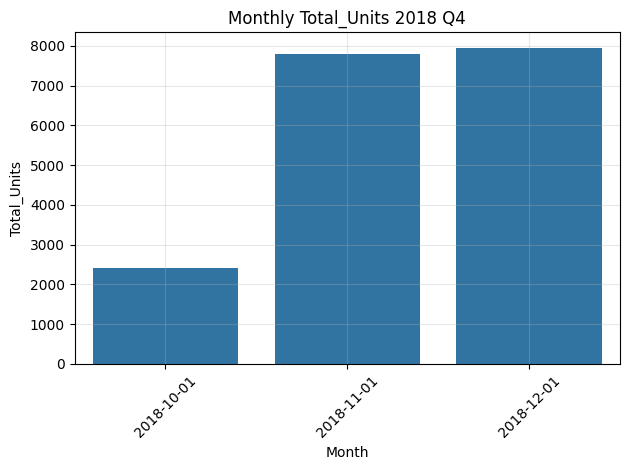

In [17]:
sns.barplot(
    x=monthly_sales_2018["month"],
    y=monthly_sales_2018["Total_Units"]
)

plt.title("Monthly Total_Units 2018 Q4")
plt.xlabel("Month")
plt.ylabel("Total_Units")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

In [18]:
sales_2019 = sales[sales['year'] == 2019]

In [19]:
monthly_sales_2019 = (
    sales_2019.groupby("month")
    .agg(
        Total_Units=("items_count", "sum"),
        Revenue=("paid_total_EGP", "sum"),
        
    )
    .reset_index()
)

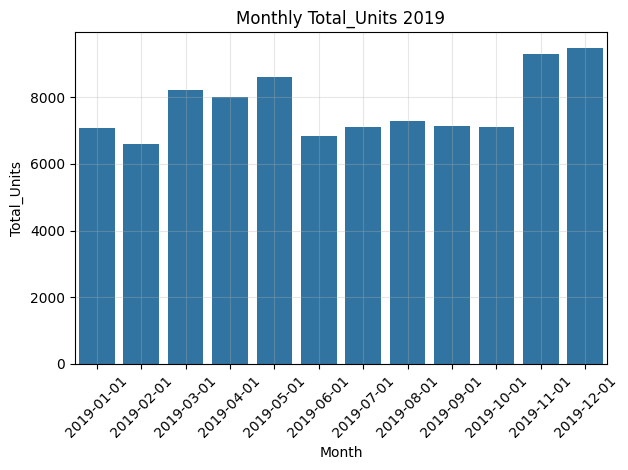

In [20]:
sns.barplot(
    x=monthly_sales_2019["month"],
    y=monthly_sales_2019["Total_Units"],
)

plt.title("Monthly Total_Units 2019")
plt.xlabel("Month")
plt.ylabel("Total_Units")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

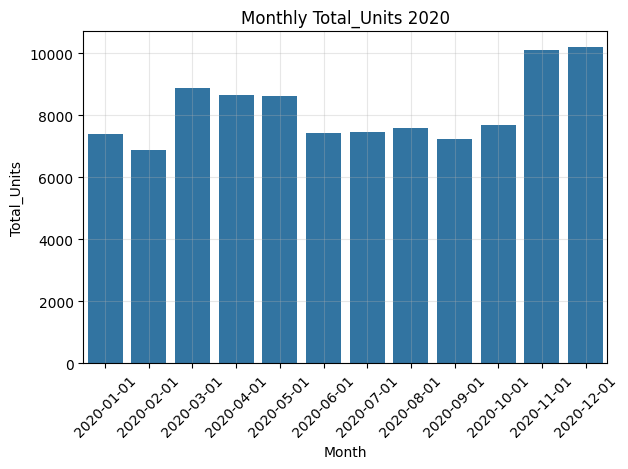

In [21]:
sales_2020 = sales[sales['year'] == 2020]

monthly_sales_2020 = (
    sales_2020.groupby("month")
    .agg(
        Total_Units=("items_count", "sum"),
        Revenue=("paid_total_EGP", "sum"),
        
    )
    .reset_index()
)

sns.barplot(
    x=monthly_sales_2020["month"],
    y=monthly_sales_2020["Total_Units"],
)

plt.title("Monthly Total_Units 2020")
plt.xlabel("Month")
plt.ylabel("Total_Units")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

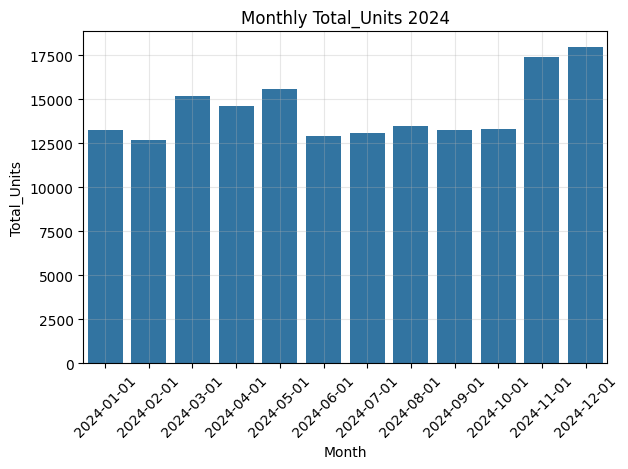

In [22]:
sales_2024 = sales[sales['year'] == 2024]

monthly_sales_2024 = (
    sales_2024.groupby("month")
    .agg(
        Total_Units=("items_count", "sum"),
        Revenue=("paid_total_EGP", "sum"),
        
    )
    .reset_index()
)

sns.barplot(
    x=monthly_sales_2024["month"],
    y=monthly_sales_2024["Total_Units"],
)

plt.title("Monthly Total_Units 2024")
plt.xlabel("Month")
plt.ylabel("Total_Units")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

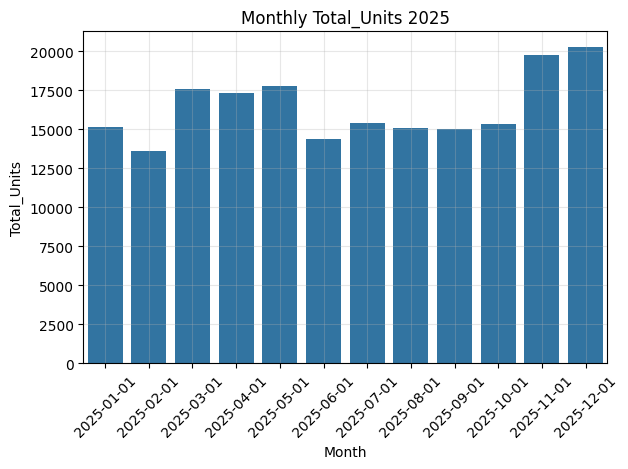

In [23]:
sales_2025 = sales[sales['year'] == 2025]

monthly_sales_2025 = (
    sales_2025.groupby("month")
    .agg(
        Total_Units=("items_count", "sum"),
        Revenue=("paid_total_EGP", "sum"),
        
    )
    .reset_index()
)

sns.barplot(
    x=monthly_sales_2025["month"],
    y=monthly_sales_2025["Total_Units"],
)

plt.title("Monthly Total_Units 2025")
plt.xlabel("Month")
plt.ylabel("Total_Units")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

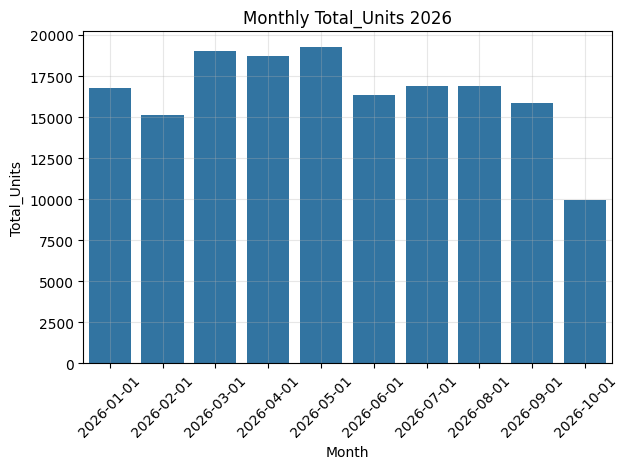

In [53]:
sales_2026 = sales[sales['year'] == 2026]

monthly_sales_2026 = (
    sales_2026.groupby("month")
    .agg(
        Total_Units=("items_count", "sum"),
        Revenue=("paid_total_EGP", "sum"),
        
    )
    .reset_index()
)

sns.barplot(
    x=monthly_sales_2026["month"],
    y=monthly_sales_2026["Total_Units"],
)

plt.title("Monthly Total_Units 2026")
plt.xlabel("Month")
plt.ylabel("Total_Units")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

## YOY Growth (Year-over-Year Growth)

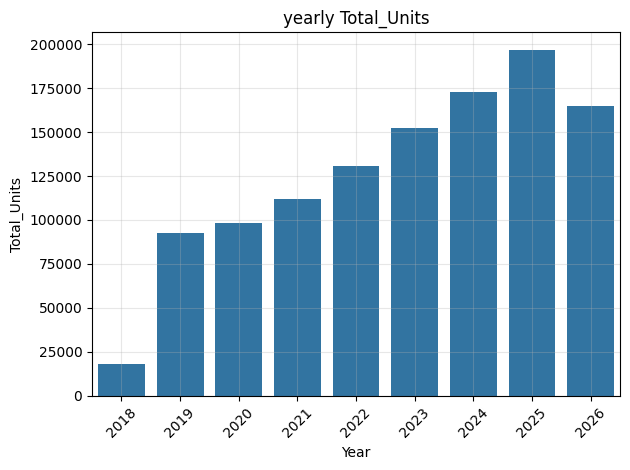

In [50]:
yearly_sales = (
    sales.groupby("year")
    .agg(
        Total_Units=("items_count", "sum"),
        Revenue=("paid_total_EGP", "sum"),
        
    )
    .reset_index()
)

sns.barplot(
    x=yearly_sales["year"],
    y=yearly_sales["Total_Units"],
)

plt.title("yearly Total_Units")
plt.xlabel("Year")
plt.ylabel("Total_Units")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

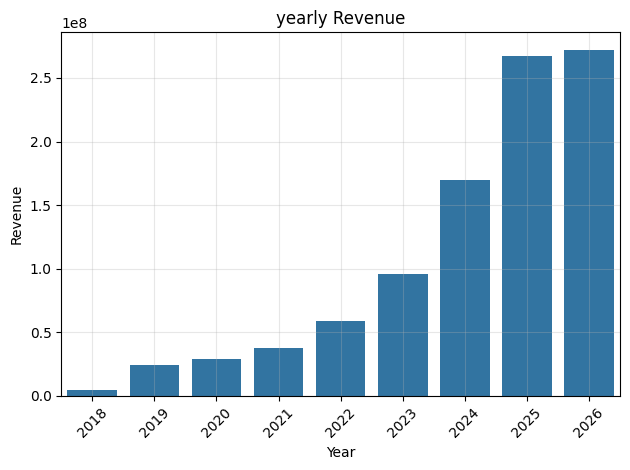

In [51]:
yearly_sales = (
    sales.groupby("year")
    .agg(
        Total_Units=("items_count", "sum"),
        Revenue=("paid_total_EGP", "sum"),
        
    )
    .reset_index()
)

sns.barplot(
    x=yearly_sales["year"],
    y=yearly_sales["Revenue"],
)

plt.title("yearly Revenue")
plt.xlabel("Year")
plt.ylabel("Revenue")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

## YOY Net Profit Growth — P/L

In [27]:
# Net Revenue
annual_rev = sales.groupby('year').agg(
    gross_sales=('gross_EGP', 'sum'),
    discounts=('discount_EGP', 'sum'),
    net_sales=('net_before_tax_EGP', 'sum')
)

In [28]:
# Returns
sr = pd.read_csv('COTTONIL_Data/02_TABLES/sales_returns.csv')
sr['year'] = pd.to_datetime(sr['return_date']).dt.year
returns = sr.groupby('year')['refund_amount_EGP'].sum().rename('returns')

In [40]:
cogs = pd.read_csv('COTTONIL_Data/02_TABLES/sales_order_items.csv', usecols=['order_date', 'quantity', 'unit_cost_EGP'])
cogs['year'] = pd.to_datetime(cogs['order_date']).dt.year
cogs['line_cogs'] = cogs['quantity'] * cogs['unit_cost_EGP']
year_cogs = cogs.groupby('year')['line_cogs'].sum().rename('year_cogs')

In [36]:
# operating_expenses
opex = pd.read_csv('COTTONIL_Data/02_TABLES/operating_expenses.csv')
opex['year'] = pd.to_datetime(opex['expense_date']).dt.year
opex_summary = opex.groupby('year')['amount_EGP'].sum().rename('opex')

In [42]:
# Payroll
pay = pd.read_csv('COTTONIL_Data/02_TABLES/payroll.csv')
pay['year'] = pd.to_datetime(pay['pay_month']).dt.year
payroll_summary = pay.groupby('year')['net_paid_EGP'].sum().rename('payroll')

In [44]:
# Combine into Audited P&L
pl = pd.concat([annual_rev, returns, year_cogs, opex_summary, payroll_summary], axis=1)
pl['net_realized_revenue'] = pl['net_sales'] - pl['returns']
pl['gross_profit'] = pl['net_realized_revenue'] - pl['year_cogs']
pl['gross_margin_%'] = (pl['gross_profit'] / pl['net_sales']) * 100
pl['total_operating_cost'] = pl['opex'] + pl['payroll']
pl['net_profit_EBIT'] = pl['gross_profit'] - pl['total_operating_cost']
pl['net_margin_%'] = (pl['net_profit_EBIT'] / pl['net_sales']) * 100
pl['yoy_net_profit_growth_%'] = pl['net_profit_EBIT'].pct_change() * 100

In [55]:
pl

,gross_sales,discounts,net_sales,returns,year_cogs,opex,payroll,net_realized_revenue,gross_profit,gross_margin_%,total_operating_cost,net_profit_EBIT,net_margin_%,yoy_net_profit_growth_%
year,,,,,,,,,,,,,,
2018,3.904067e+06,169198.00,3.734869e+06,52862.75,2.295023e+06,1137894.38,9872.10,3.682007e+06,1386983.37,37.136061,1147766.48,239216.89,6.404960,NaN
2019,2.259336e+07,973154.90,2.162020e+07,362803.56,1.333754e+07,6287545.60,630865.44,2.125740e+07,7919857.89,36.631743,6918411.04,1001446.85,4.631995,318.635511
2020,2.687858e+07,1169239.83,2.570934e+07,432249.85,1.585801e+07,7219580.04,2519962.02,2.527709e+07,9419083.63,36.636813,9739542.06,-320458.43,-1.246467,-131.999544
2021,3.418501e+07,1468143.93,3.271686e+07,554011.43,2.018437e+07,7866173.20,4756587.00,3.216285e+07,11978477.84,36.612551,12622760.20,-644282.36,-1.969267,101.050214
2022,5.392593e+07,2347452.39,5.157847e+07,878713.39,3.189948e+07,10838114.01,7604088.30,5.069976e+07,18800282.45,36.449861,18442202.31,358080.14,0.694243,-155.578138
2023,8.796749e+07,3819558.55,8.414793e+07,1340719.60,5.186266e+07,15279914.38,10993526.92,8.280722e+07,30944553.38,36.773990,26273441.30,4671112.08,5.551072,1204.487895
2024,1.554783e+08,6695959.36,1.487824e+08,2358349.88,9.166635e+07,23340296.75,15760625.75,1.464240e+08,54757647.12,36.803859,39100922.50,15656724.62,10.523241,235.181951
2025,2.447121e+08,10573513.91,2.341385e+08,3739170.37,1.443517e+08,31906386.96,13790700.96,2.303994e+08,86047657.70,36.750744,45697087.92,40350569.78,17.233629,157.720377
2026,2.495510e+08,10705379.36,2.388456e+08,4195623.51,1.472607e+08,31767764.00,3456287.00,2.346500e+08,87389251.78,36.588179,35224051.00,52165200.78,21.840554,29.279961


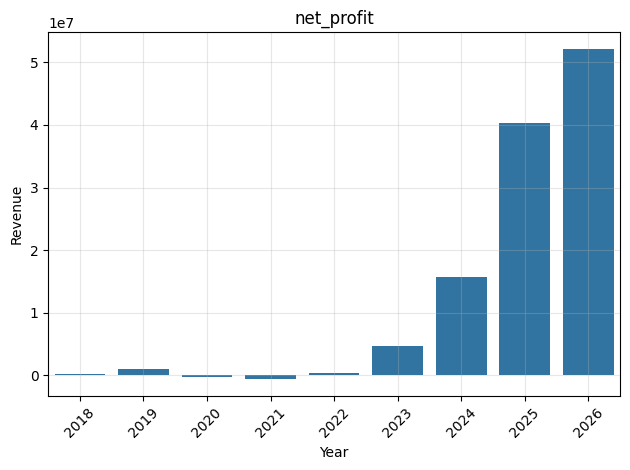

In [54]:
sns.barplot(
    x=pl.index,
    y=pl["net_profit_EBIT"],
)

plt.title("net_profit")
plt.xlabel("Year")
plt.ylabel("Revenue")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

# Sales Forecasting Model